# 05 · Readability  _(owner: M5 — Laura)_

**Goal:** understand how our readability metrics behave before tuning the Readability agent (target: Flesch-Kincaid ≤ 8 on ≥ 80% of outputs, without changing facts).

1. What `readability_scores()` and `meets_readability_target()` measure
2. Jargon-heavy vs. plain version of the same sentence
3. 20 PLABA pairs (technical abstract vs. human plain rewrite) — score both sides, chart grade levels

In [11]:
# One-time: newer textstat needs the CMU pronouncing dictionary for syllable counts


import pandas as pd
import matplotlib.pyplot as plt
from clearmed.eval_harness import readability_scores, meets_readability_target

## 1 · What the harness measures

| Metric | What it is | Formula idea |
|---|---|---|
| **Flesch-Kincaid grade** | US school grade needed to read it | `0.39 × words/sentence + 11.8 × syllables/word − 15.59` |
| **SMOG** | Grade level from polysyllabic (3+ syllable) words | common in health-literacy research |
| **Jargon density** | share of words *not* on the Dale-Chall list of ~3,000 familiar words | proxy for jargon, not medical-specific |
| **Word count** | length | |

`meets_readability_target(text)` → `True` if FK grade ≤ 8.

⚠️ Note: these are **surface formulas** — they only count sentence length and syllables. They don't know if the text is actually understandable, correct, or complete. (Like Lexile scores for kids' books.)

## 2 · Same sentence, two versions

In [12]:
jargon = ("Patient was prescribed a beta-adrenergic antagonist for management of essential "
          "hypertension; follow-up with cardiology is recommended in two weeks.")
plain = "You got a new medicine to lower your blood pressure. See your heart doctor in two weeks."

compare = pd.DataFrame({"jargon": readability_scores(jargon), "plain": readability_scores(plain)})
compare.loc["meets_target"] = [meets_readability_target(jargon), meets_readability_target(plain)]
compare

,jargon,plain
flesch_kincaid_grade,19.146316,2.995588
smog_index,19.287187,7.168622
jargon_density,0.526316,0.117647
word_count,19.000000,17.000000
meets_target,0.000000,1.000000


## 3 · 20 PLABA pairs (technical abstract → human plain rewrite)

Source: PLABA test split from OSF (https://osf.io/rnpmf), saved as `data/plaba_test.csv`. One adaptation per abstract, first 20 abstracts.

In [ ]:
pd.read_csv("../data/plaba_test.csv")
#note that the plaba test are 

,question,pmid,input_text,target_text,Adaptation_Version,Question_Type
0,5,30377698,Purpose: Osteoarthritis of the knee is a commo...,"Knee osteoarthritis is a common disease, often...",2,C
1,5,30377698,Purpose: Osteoarthritis of the knee is a commo...,Osteoarthritis of the knee is a common disease...,2,C
2,5,32631287,Background: This study aimed to compare the ar...,This work compared internal joint drainage of ...,2,C
3,5,32631287,Background: This study aimed to compare the ar...,"Popliteal cysts, or Baker's cysts, are abnorm...",2,C
4,5,21636864,Objective: To review the results of arthroscop...,The objective is to review the results and iss...,2,C
...,...,...,...,...,...,...
143,68,32681497,SARS-CoV-2 infection is characterized by a pro...,SARS-CoV-2 infection (a viral lung infection) ...,2,C
144,68,35240553,Background: Several studies have suggested tha...,"As background for this article, several studie...",2,C
145,68,35136706,The importance of ferritin as an inflammatory ...,The importance of ferritin (an iron-containing...,2,C
146,68,34924800,"Ferritin, which includes twenty-four light and...","Ferritin (an iron-containing protein), which h...",2,C


In [13]:
plaba = pd.read_csv("../data/plaba_test.csv").drop_duplicates("pmid").head(20).reset_index(drop=True)

rows = []
for i, r in plaba.iterrows():
    t, p = readability_scores(r.input_text), readability_scores(r.target_text)
    rows.append({"pair": i + 1,
                 "fk_technical": t["flesch_kincaid_grade"], "fk_plain": p["flesch_kincaid_grade"],
                 "smog_technical": t["smog_index"], "smog_plain": p["smog_index"],
                 "jargon_technical": t["jargon_density"], "jargon_plain": p["jargon_density"],
                 "words_technical": t["word_count"], "words_plain": p["word_count"]})
scores = pd.DataFrame(rows)
scores.round(2)

,pair,fk_technical,fk_plain,smog_technical,smog_plain,jargon_technical,jargon_plain,words_technical,words_plain
0,1,13.40,11.63,13.82,12.89,0.29,0.24,252,180
1,2,11.53,11.20,14.55,14.84,0.21,0.21,292,245
2,3,14.59,9.84,15.32,11.65,0.33,0.26,138,121
3,4,15.36,14.98,16.77,16.53,0.32,0.32,226,187
4,5,13.45,15.23,15.31,16.16,0.33,0.29,204,257
5,6,12.24,11.87,14.29,13.97,0.28,0.24,192,220
6,7,18.24,16.44,19.29,17.88,0.31,0.32,120,164
7,8,18.60,19.28,19.29,19.14,0.28,0.27,173,224
8,9,10.79,11.32,13.27,13.37,0.20,0.19,250,305
9,10,11.51,11.39,13.02,13.52,0.34,0.30,123,191


In [14]:
summary = scores.drop(columns="pair").agg(["mean", "min", "max"]).round(2)
print("Plain rewrites at <= 8th grade:", (scores.fk_plain <= 8).sum(), "/ 20")
print("Pairs where the plain version scored HARDER:", (scores.fk_plain > scores.fk_technical).sum(), "/ 20")
summary

Plain rewrites at <= 8th grade: 0 / 20
Pairs where the plain version scored HARDER: 3 / 20


,fk_technical,fk_plain,smog_technical,smog_plain,jargon_technical,jargon_plain,words_technical,words_plain
mean,15.59,13.88,16.54,15.16,0.32,0.27,178.9,196.45
min,10.79,9.84,13.02,11.65,0.20,0.17,52.0,39.00
max,19.75,19.28,19.29,19.14,0.41,0.40,292.0,305.00


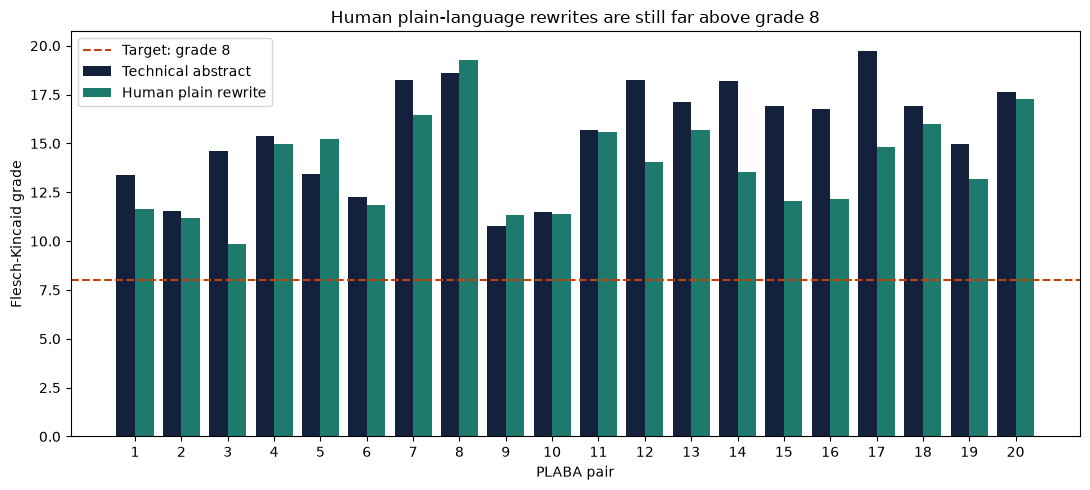

In [15]:
fig, ax = plt.subplots(figsize=(11, 5))
x = scores.pair
ax.bar(x - 0.2, scores.fk_technical, 0.4, label="Technical abstract", color="#14213D")
ax.bar(x + 0.2, scores.fk_plain, 0.4, label="Human plain rewrite", color="#1F7A6E")
ax.axhline(8, color="#C2410C", ls="--", label="Target: grade 8")
ax.set_xlabel("PLABA pair"); ax.set_ylabel("Flesch-Kincaid grade"); ax.set_xticks(x)
ax.set_title("Human plain-language rewrites are still far above grade 8")
ax.legend(); plt.tight_layout(); plt.show()

## Findings

- Plain rewrites drop FK by only ~1.7 grades on average (15.6 → 13.9); **0 of 20** reach grade 8.
- In some pairs the plain version scores *harder*: experts often keep the term and add an explanation in parentheses (e.g. "fibrosis" → "scarring (fibrosis)"), which makes sentences longer — and FK punishes length.
- So FK alone can **penalize good explaining**. PLABA is abstract-level research text, not discharge notes, so grade 8 may be unrealistic here.

**Implications for the Readability agent:** don't optimize FK blindly (it rewards short choppy sentences and deleting detail); report FK + SMOG + jargon together; check facts are kept (Verifier).

**Next:** run the same scoring on the single-LLM baseline outputs; test FK on short discharge-style text where grade 8 is realistic.

# Week 3 · Do the metrics agree? Which words drive the score?

In [16]:
import textstat as ts

METRICS = {
    "FK grade": ts.flesch_kincaid_grade,          # grade; higher = harder
    "SMOG": ts.smog_index,                        # grade; based on 3+ syllable words
    "Gunning Fog": ts.gunning_fog,                # grade; sentence length + "complex" words
    "Coleman-Liau": ts.coleman_liau_index,        # grade; uses LETTERS per word, not syllables
    "Dale-Chall": ts.dale_chall_readability_score, # uses a list of ~3,000 familiar words
    "Flesch Reading Ease": ts.flesch_reading_ease,  # 0-100; HIGHER = EASIER (opposite direction!)
}

long_rows = []
for _, r in plaba.iterrows():
    for side, text in [("technical", r.input_text), ("plain", r.target_text)]:
        row = {name: f(text) for name, f in METRICS.items()}
        row.update(side=side, pmid=r.pmid)
        long_rows.append(row)
metrics = pd.DataFrame(long_rows)

# Spearman = rank correlation: do two metrics ORDER the 40 texts the same way?
metrics[list(METRICS)].corr(method="spearman").round(2)

,FK grade,SMOG,Gunning Fog,Coleman-Liau,Dale-Chall,Flesch Reading Ease
FK grade,1.00,0.94,0.94,0.76,0.51,-0.92
SMOG,0.94,1.00,0.99,0.75,0.62,-0.86
Gunning Fog,0.94,0.99,1.00,0.80,0.66,-0.89
Coleman-Liau,0.76,0.75,0.80,1.00,0.75,-0.91
Dale-Chall,0.51,0.62,0.66,0.75,1.00,-0.62
Flesch Reading Ease,-0.92,-0.86,-0.89,-0.91,-0.62,1.00


In [17]:
wide = metrics.pivot(index="pmid", columns="side")
for name in METRICS:
    change = wide[(name, "plain")] - wide[(name, "technical")]
    easier = (change > 0).sum() if name == "Flesch Reading Ease" else (change < 0).sum()
    print(f"{name:20s} plain easier in {easier}/20 pairs, mean change {change.mean():+.2f}")

FK grade             plain easier in 17/20 pairs, mean change -1.72
SMOG                 plain easier in 16/20 pairs, mean change -1.37
Gunning Fog          plain easier in 17/20 pairs, mean change -2.21
Coleman-Liau         plain easier in 18/20 pairs, mean change -2.35
Dale-Chall           plain easier in 17/20 pairs, mean change -0.67
Flesch Reading Ease  plain easier in 18/20 pairs, mean change +13.49


In [18]:
# WHY did FK drop? FK = 0.39*(words/sentence) + 11.8*(syllables/word) - 15.59
for side, col in [("technical", "input_text"), ("plain", "target_text")]:
    s = plaba[col]
    wps = (s.map(ts.lexicon_count) / s.map(ts.sentence_count)).mean()
    spw = (s.map(ts.syllable_count) / s.map(ts.lexicon_count)).mean()
    print(f"{side:10s} words/sentence={wps:.1f}  syllables/word={spw:.2f}")

technical  words/sentence=21.3  syllables/word=1.94
plain      words/sentence=22.0  syllables/word=1.77


In [19]:
# Which "difficult" words appear most? (textstat = not on the Dale-Chall familiar list)
from collections import Counter
tech_words, plain_words = Counter(), Counter()
for t in plaba.input_text:  tech_words.update(w.lower() for w in ts.difficult_words_list(t))
for t in plaba.target_text: plain_words.update(w.lower() for w in ts.difficult_words_list(t))
jargon = pd.DataFrame([(w, n, plain_words[w], ts.syllable_count(w)) for w, n in tech_words.most_common(25)],
                      columns=["word", "count_technical", "count_plain", "syllables"])
jargon

,word,count_technical,count_plain,syllables
0,asthma,13,14,2
1,patients,12,12,2
2,treatment,11,13,2
3,results,10,6,2
4,arthroscopic,10,8,3
5,clinical,9,5,3
6,development,9,5,4
7,disease,8,9,2
8,effective,8,4,3
9,intraarticular,7,2,5


### Findings (week 3)
- **Metrics mostly agree.** FK, SMOG and Gunning Fog rank texts almost identically (Spearman ≈ 0.94–0.99) because they're all built on sentence length + long words. Dale-Chall agrees least (≈0.5) because it uses a word list, not syllables. All 6 say the plain side is easier in 16–18 of 20 pairs.
- **The drop comes from shorter words, not shorter sentences.** Plain rewrites have slightly *longer* sentences (21.3 → 22.0 words) but fewer syllables per word (1.94 → 1.77).
- **`jargon_density` is not real medical jargon.** The Dale-Chall list flags everyday words like *patients, treatment, results* alongside true jargon like *arthroscopic, intraarticular*. A medical term list (UMLS / MedlinePlus) would be better.


## Ready for M4's baseline outputs

In [20]:
def score_outputs(texts, label="baseline"):
    """Score a list of model outputs -> one row per output + summary of the success criterion."""
    df = pd.DataFrame([readability_scores(t) for t in texts])
    df["meets_target"] = [meets_readability_target(t) for t in texts]
    print(f"{label}: {df.meets_target.mean():.0%} at <= grade 8 (goal: >= 80%), "
          f"mean FK {df.flesch_kincaid_grade.mean():.1f}")
    return df

# When M4 shares outputs (e.g. a CSV with an 'output' column):
# baseline = pd.read_csv("../data/m4/baseline_outputs.csv")
# score_outputs(baseline["output"].tolist())